# Generate output files of ERA5 precipitation spatially averaged over the VICWaCI regions

Modified from: https://github.com/stellema/VicWaCI/blob/master/data_preparation/agcd_monthly.ipynb

In [ ]:
import cartopy
import cartopy.crs as ccrs
from datetime import datetime
import geopandas as gp
import glob
import matplotlib.pyplot as plt
import numpy as np
import regionmask
import xarray as xr

## Read precipitation data

In [2]:
# Check what files are available
files_all = sorted(
    glob.glob(f"/g/data/rt52/era5/single-levels/reanalysis/tp/*/tp_era5_oper_sfc_*.nc")
)
print(files_all[0])
print(files_all[-1])

/g/data/rt52/era5/single-levels/reanalysis/tp/1940/tp_era5_oper_sfc_19400101-19400131.nc
/g/data/rt52/era5/single-levels/reanalysis/tp/2026/tp_era5_oper_sfc_20260601-20260630.nc


In [3]:
# Generate list of files (1940-2025 plus an extra month)
date_range = xr.date_range(f"1940-01-01", f"2026-01-31", freq="1MS")
# Dates used to subset the data later
date_bnds = ["1940-01-01", "2025-12-31"]

files = []
for dt in date_range:
    files_year = sorted(
        glob.glob(f"/g/data/rt52/era5/single-levels/reanalysis/tp/{dt.year}/tp_era5_oper_sfc_*.nc")
    )
    files.append(files_year)
files = np.concatenate(files)

# Subset files to only include those within the date range
dates = np.array([datetime.strptime(file[-20:-12], "%Y%m%d") for file in files])

file_mask = dates <= date_range[-1]
files = files[file_mask]
files

array(['/g/data/rt52/era5/single-levels/reanalysis/tp/1940/tp_era5_oper_sfc_19400101-19400131.nc',
       '/g/data/rt52/era5/single-levels/reanalysis/tp/1940/tp_era5_oper_sfc_19400201-19400229.nc',
       '/g/data/rt52/era5/single-levels/reanalysis/tp/1940/tp_era5_oper_sfc_19400301-19400331.nc',
       ...,
       '/g/data/rt52/era5/single-levels/reanalysis/tp/2025/tp_era5_oper_sfc_20251101-20251130.nc',
       '/g/data/rt52/era5/single-levels/reanalysis/tp/2025/tp_era5_oper_sfc_20251201-20251231.nc',
       '/g/data/rt52/era5/single-levels/reanalysis/tp/2026/tp_era5_oper_sfc_20260101-20260131.nc'],
      shape=(12385,), dtype='<U88')

In [4]:
def preprocess(ds):
    """Preprocess the ERA5 dataset."""

    # Select only the "tp" variable (drops other variables like "lon_bnds", etc)
    ds = ds[["tp"]]

    # Select the region of interest (Victoria, Australia)
    # NB swap N/S for ERA5
    ds = ds.sel(latitude=slice(-33.5, -39.5), longitude=slice(140, 151))
    return ds


ds = xr.open_mfdataset(files, chunks="auto", preprocess=preprocess)
ds

<xarray.Dataset> Size: 7GB
Dimensions:    (time: 754625, latitude: 25, longitude: 45)
Coordinates:
  * time       (time) datetime64[ns] 6MB 1940-01-01T07:00:00 ... 2026-01-31T2...
  * latitude   (latitude) float32 100B -33.5 -33.75 -34.0 ... -39.0 -39.25 -39.5
  * longitude  (longitude) float32 180B 140.0 140.2 140.5 ... 150.5 150.8 151.0
Data variables:
    tp         (time, latitude, longitude) float64 7GB dask.array<chunksize=(186, 25, 45), meta=np.ndarray>
Attributes:
    Conventions:  CF-1.6
    history:      2024-01-08 03:21:12 UTC+1100 by era5_replication_tools-1.12...
    license:      Licence to use Copernicus Products: https://apps.ecmwf.int/...
    summary:      ERA5 is the fifth generation ECMWF atmospheric reanalysis o...
    title:        ERA5 single-levels reanalysis total_precipitation 19400101-...

In [ ]:
# Convert from m to mm
if ds["tp"].attrs["units"] == "m":
    ds["tp"] *= 1e3
    ds["tp"].attrs["units"] = "mm"

# Rename coords
ds = ds.rename({"latitude": "lat", "longitude": "lon"})
ds

In [ ]:
# Ensure to exclude first processing step (records last hour of previous day) using 'end_day'
ds_daily = ds.resample(time="24h", label="left", origin="end_day").sum("time")

# Remove before/after times that aren't based on full days
ds_daily = ds_daily.sel(time=slice(*date_bnds))
ds_daily

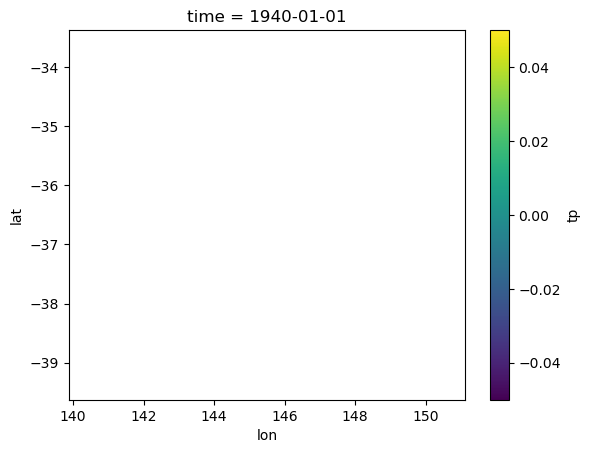

In [7]:
# Check this works as expected
# Calculate a single daily total manually
tmp = ds.tp.isel(time=slice(1, None)).isel(time=slice(24)).sum("time")
diff = ds_daily.tp.isel(time=0) - tmp
# diff.plot()
# Plot non-NaN differences
xr.where(ds_daily.tp.isel(time=0), np.nan, diff).plot()

## Apply shapefiles to data

In [ ]:
valid_regions = [
    "victoria",
    "north_east_victoria",
    "north_west_victoria",
    "south_east_victoria",
    "south_west_victoria",
]


def read_shapefile(region_name):
    assert region_name in valid_regions
    gdf = gp.read_file(f"/g/data/xv83/dbi599/vicwaci/shapefiles/{region_name}.shp")
    region = regionmask.from_geopandas(gdf)

    return region


def plot_frac(frac):
    fig = plt.figure(figsize=[8, 4])
    ax = fig.add_subplot(111, projection=ccrs.PlateCarree())
    frac.plot(ax=ax, transform=ccrs.PlateCarree())
    ax.coastlines()
    ax.add_feature(cartopy.feature.STATES)
    plt.show()


def spatial_mean(ds, region_name, outfile, freq="D"):
    """Calculate spatial mean"""

    region = read_shapefile(region_name)
    frac = region.mask_3D_frac_approx(ds).isel(region=0)
    plot_frac(frac)

    weights = np.cos(np.deg2rad(ds["lat"]))
    spatial_mean = ds["tp"].weighted(frac * weights).mean(dim=("lat", "lon"))
    spatial_mean = np.round(spatial_mean, decimals=2)

    spatial_mean = spatial_mean.drop_vars(["region", "abbrevs", "names"])
    spatial_mean = spatial_mean.to_dataset()
    spatial_mean["time"].attrs = {
        "axis": "T",
        "standard_name": "time",
        "long_name": "time",
    }
    if freq == "D":
        spatial_mean["tp"].attrs = {
            "units": "mm",
            "long_name": "spatial mean daily precipitation",
        }
    else:
        spatial_mean["tp"].attrs = {
            "units": "mm",
            "long_name": "spatial mean monthly precipitation",
        }
    spatial_mean.attrs = {
        "summary": f"total daily precipitation averaged over the {region_name} region",
        "id": "ERA5",
        "license": ds.attrs["license"],
    }

    spatial_mean.attrs["history"] = (
        ds.attrs["history"]
        + f"\n{datetime.now().strftime('%Y-%m-%d %H:%M:%S')} by era5_daily.ipynb: Created {outfile}"
    )

    spatial_mean.to_netcdf(
        outfile,
        compute=True,
        encoding={
            "time": {"_FillValue": None},
            "tp": {"_FillValue": None, "zlib": True, "complevel": 4, "shuffle": True},
        },
    )
    spatial_mean.close()

    print(outfile)

/g/data/xv83/as3189/vicwaci/data/era5_precip_total_victoria_daily_1940-2025.nc


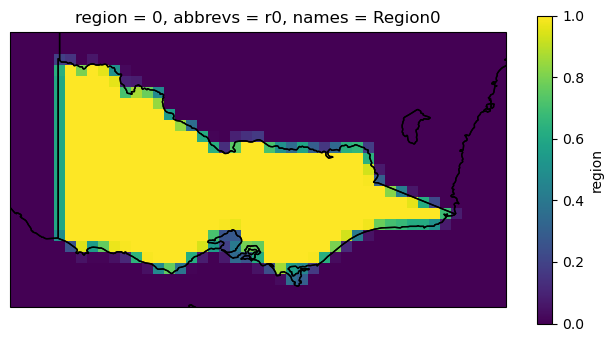

/g/data/xv83/as3189/vicwaci/data/era5_precip_total_victoria_daily_1940-2025.nc
/g/data/xv83/as3189/vicwaci/data/era5_precip_total_north-east-victoria_daily_1940-2025.nc


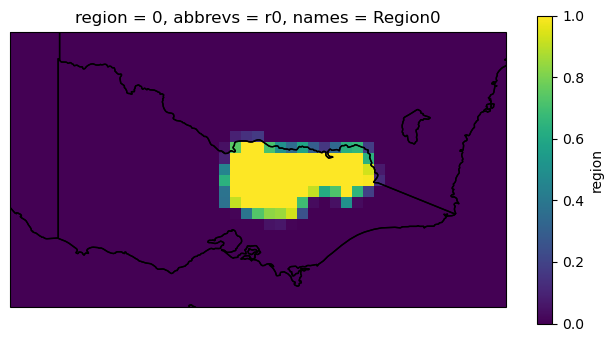

/g/data/xv83/as3189/vicwaci/data/era5_precip_total_north-east-victoria_daily_1940-2025.nc
/g/data/xv83/as3189/vicwaci/data/era5_precip_total_north-west-victoria_daily_1940-2025.nc


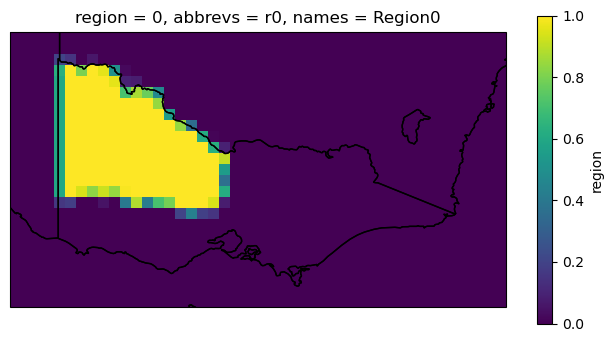

/g/data/xv83/as3189/vicwaci/data/era5_precip_total_north-west-victoria_daily_1940-2025.nc
/g/data/xv83/as3189/vicwaci/data/era5_precip_total_south-east-victoria_daily_1940-2025.nc


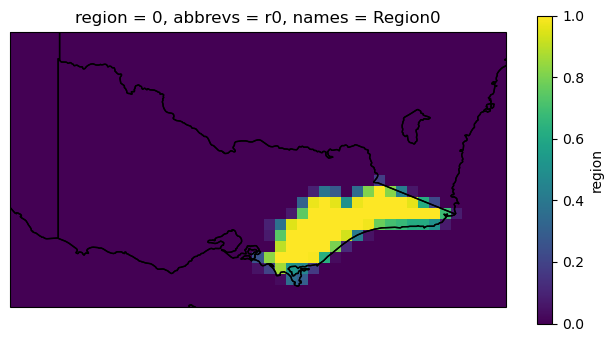

/g/data/xv83/as3189/vicwaci/data/era5_precip_total_south-east-victoria_daily_1940-2025.nc
/g/data/xv83/as3189/vicwaci/data/era5_precip_total_south-west-victoria_daily_1940-2025.nc


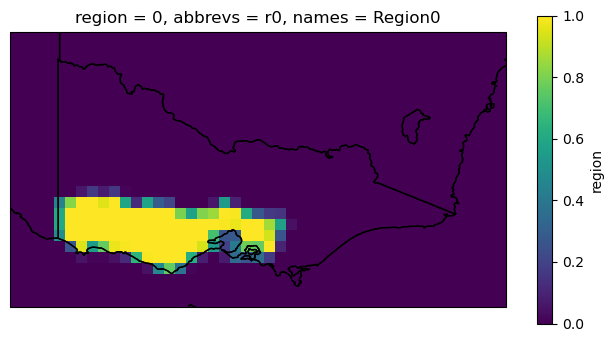

/g/data/xv83/as3189/vicwaci/data/era5_precip_total_south-west-victoria_daily_1940-2025.nc


In [9]:
for region in valid_regions:
    region_fname = region.replace("_", "-")
    y1, y2 = [int(y) for y in ds_daily.time[[0, -1]].dt.year]
    outfile = (
        f"/g/data/xv83/as3189/vicwaci/data/era5_precip_total_{region_fname}_daily_{y1}-{y2}.nc"
    )
    print(outfile)
    spatial_mean(ds_daily, region, outfile)

In [ ]:
ds_monthly = ds_daily.resample(time="ME").sum("time")
ds_monthly

<xarray.Dataset> Size: 9MB
Dimensions:  (time: 1032, lat: 25, lon: 45)
Coordinates:
  * time     (time) datetime64[ns] 8kB 1940-01-31 1940-02-29 ... 2025-12-31
  * lat      (lat) float32 100B -33.5 -33.75 -34.0 -34.25 ... -39.0 -39.25 -39.5
  * lon      (lon) float32 180B 140.0 140.2 140.5 140.8 ... 150.5 150.8 151.0
Data variables:
    tp       (time, lat, lon) float64 9MB dask.array<chunksize=(1, 25, 45), meta=np.ndarray>
Attributes:
    Conventions:  CF-1.6
    history:      2024-01-08 03:21:12 UTC+1100 by era5_replication_tools-1.12...
    license:      Licence to use Copernicus Products: https://apps.ecmwf.int/...
    summary:      ERA5 is the fifth generation ECMWF atmospheric reanalysis o...
    title:        ERA5 single-levels reanalysis total_precipitation 19400101-...

/g/data/xv83/as3189/vicwaci/data/era5_precip_total_victoria_monthly_1940-2025.nc


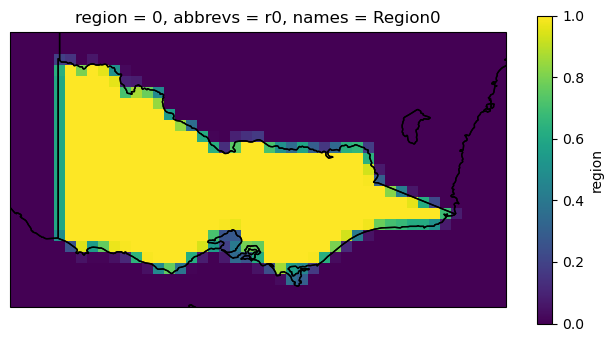

/g/data/xv83/as3189/vicwaci/data/era5_precip_total_victoria_monthly_1940-2025.nc
/g/data/xv83/as3189/vicwaci/data/era5_precip_total_north-east-victoria_monthly_1940-2025.nc


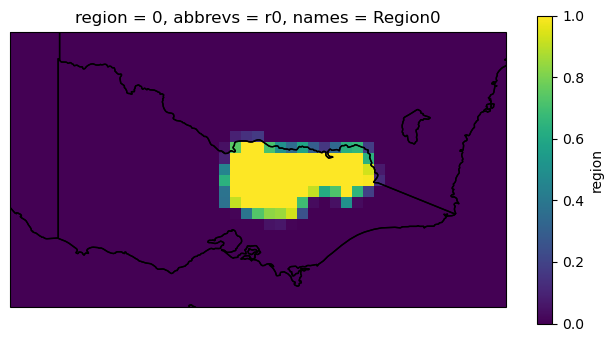

/g/data/xv83/as3189/vicwaci/data/era5_precip_total_north-east-victoria_monthly_1940-2025.nc
/g/data/xv83/as3189/vicwaci/data/era5_precip_total_north-west-victoria_monthly_1940-2025.nc


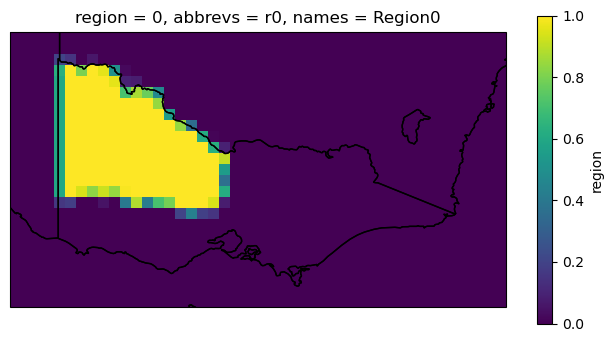

/g/data/xv83/as3189/vicwaci/data/era5_precip_total_north-west-victoria_monthly_1940-2025.nc
/g/data/xv83/as3189/vicwaci/data/era5_precip_total_south-east-victoria_monthly_1940-2025.nc


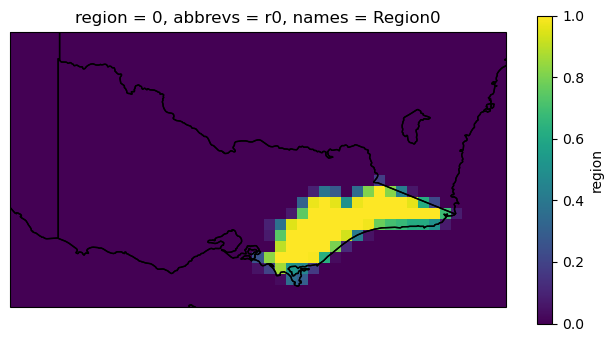

/g/data/xv83/as3189/vicwaci/data/era5_precip_total_south-east-victoria_monthly_1940-2025.nc
/g/data/xv83/as3189/vicwaci/data/era5_precip_total_south-west-victoria_monthly_1940-2025.nc


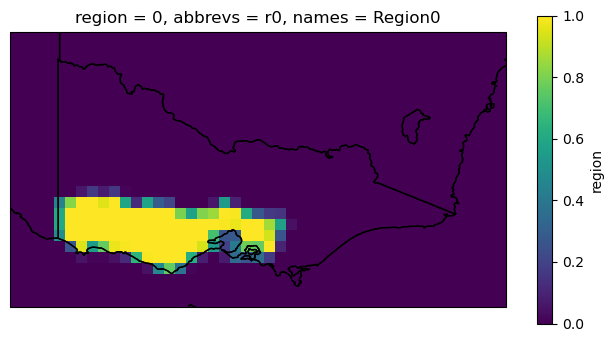

/g/data/xv83/as3189/vicwaci/data/era5_precip_total_south-west-victoria_monthly_1940-2025.nc


In [ ]:
for region in valid_regions:
    region_fname = region.replace("_", "-")
    y1, y2 = [int(y) for y in ds_daily.time[[0, -1]].dt.year]
    outfile = (
        f"/g/data/xv83/as3189/vicwaci/data/era5_precip_total_{region_fname}_monthly_{y1}-{y2}.nc"
    )
    print(outfile)
    spatial_mean(ds_monthly, region, outfile, freq="M")